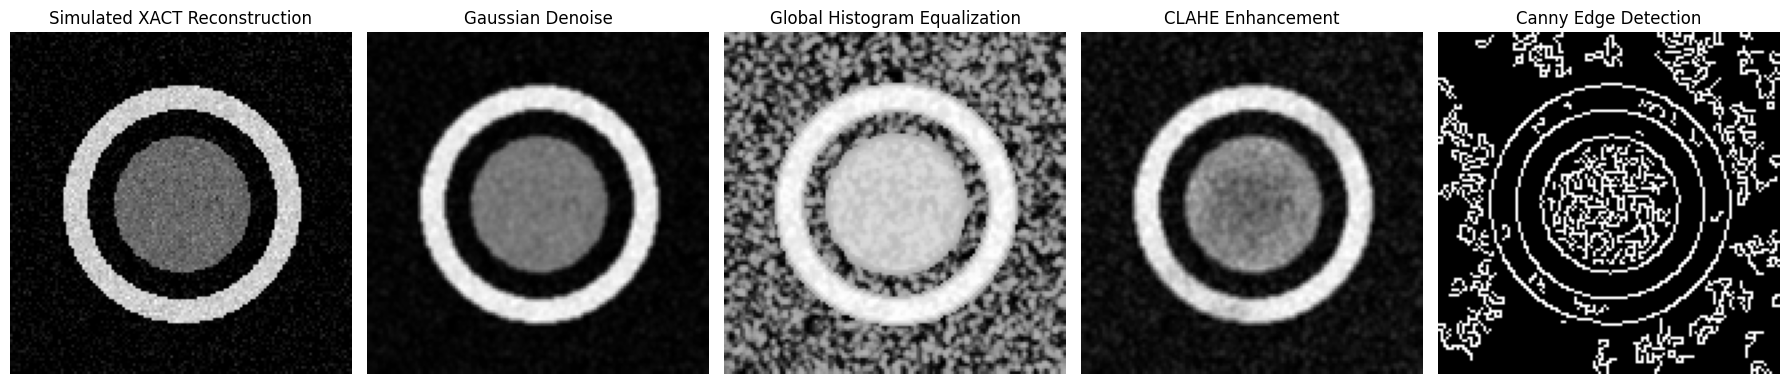

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ========== 生成一张模拟 XACT 骨骼重建灰度图 ==========
size = 128
img = np.zeros((size, size), dtype=np.uint8)
# 画环形骨骼轮廓，模拟XACT重建的骨结构
cv2.ellipse(img, (64,64), (40,40), 0, 0, 360, 160, 8)
cv2.ellipse(img, (64,64), (25,25), 0, 0, 360, 80, -1)
# 加仿真噪声，还原k-Wave重建图自带噪声
noise = np.random.normal(0, 12, img.shape).astype(np.int16)
img = np.clip(img.astype(np.int16)+noise, 0, 255).astype(np.uint8)

# ========== OpenCV 图像处理流水线（和课程知识点对应） ==========
blur = cv2.GaussianBlur(img, (3,3), 0)                # 高斯降噪
eq = cv2.equalizeHist(blur)                           # 全局直方图均衡
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
clahe_img = clahe.apply(blur)                         # CLAHE局部对比度增强
edge = cv2.Canny(clahe_img, 40, 140)                  # Canny边缘检测

# ========== 绘制对比可视化图 ==========
plt.figure(figsize=(18,4))
plt.subplot(1,5,1)
plt.title("Simulated XACT Reconstruction")
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,5,2)
plt.title("Gaussian Denoise")
plt.imshow(blur, cmap="gray")
plt.axis("off")

plt.subplot(1,5,3)
plt.title("Global Histogram Equalization")
plt.imshow(eq, cmap="gray")
plt.axis("off")

plt.subplot(1,5,4)
plt.title("CLAHE Enhancement")
plt.imshow(clahe_img, cmap="gray")
plt.axis("off")

plt.subplot(1,5,5)
plt.title("Canny Edge Detection")
plt.imshow(edge, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()4